# Predicción del puntaje global de la prueba Saber 11: modelos avanzados, evaluación e interpretabilidad

### Andrés Giovanny Rubiano Muñoz "Andy Rubiano"

**Maestría en Inteligencia Artificial**
**Universidad de La Salle**

**Ciencia de Datos**

---

**Actividad:** Proyecto Integrador de Ciencia de Datos | Fase 3 · Actividades 5 y 6: *Modelos avanzados y ajuste de hiperparámetros* y *Evaluación comparativa e interpretabilidad* (**Entregable 3**).

**Caso de estudio:** *Resultados únicos Saber 11*, ICFES, periodo **2022-4**, desde la copia congelada en Kaggle [`andyrubiano/saber-11-resultados-2022-4`](https://www.kaggle.com/datasets/andyrubiano/saber-11-resultados-2022-4) (CC BY-SA 4.0).

**Punto de partida:** el conjunto limpio, la partición 70/15/15 y los dos preprocesadores de la fase 2 (cuaderno `02_preparacion_y_baseline.ipynb`), y la regresión Ridge de referencia con MAE de 34,15 puntos y R² de 0,338 en prueba.

**Modelos comparados:** Ridge (referencia), *gradient boosting* por histogramas y *random forest*, con hiperparámetros ajustados por validación cruzada.

**Producto de este cuaderno:** los modelos entrenados, la tabla comparativa de métricas, la importancia de variables (permutación y SHAP), el análisis de errores y las predicciones sobre el conjunto de prueba, guardados en `models/` y `data/processed/` para el cuaderno de la fase 4.

## 1. Objetivo y protocolo

Este cuaderno cubre los **objetivos específicos 4 y 5** del proyecto: entrenar y comparar al menos dos modelos adicionales al de referencia, ajustar sus hiperparámetros con validación cruzada, evaluarlos con MAE, RMSE y R², e interpretar el modelo final (importancia de variables y análisis de errores).

El protocolo viene del plan de cómputo (`docs/plan-computo-colab.md`) y de las conclusiones de la fase 2:

1.  **Mismos datos, misma partición.** Se cargan los artefactos de la fase 2; si no existen (por ejemplo, en una sesión nueva de Colab) se reconstruyen con el mismo código y la misma semilla, de modo que la partición es idéntica.
2.  **Dos familias de modelos sobre dos representaciones.** Ridge usa la matriz *one-hot* (`prep_lineal`); boosting y *random forest* usan los códigos enteros con máscara de categóricas (`prep_arboles`).
3.  **Búsqueda de hiperparámetros sobre una muestra.** `RandomizedSearchCV` con 3 pliegues sobre 100.000 filas de entrenamiento, optimizando el MAE; la celda de control de tiempo decide cuántas combinaciones se exploran.
4.  **Reentrenamiento final con todo el entrenamiento** y una sola evaluación en prueba. La validación sirve para comparar modelos sin tocar la prueba.
5.  **Interpretación sobre una muestra de 5.000 filas de prueba**: importancia por permutación, valores SHAP y dependencia parcial, en lugar de coeficientes, que la fase 2 mostró inestables por la colinealidad.
6.  **Artefactos guardados** con `joblib` y CSV, para retomar si la sesión se interrumpe y para que la fase 4 no reentrene nada.

Los modelos adicionales se eligieron por su adecuación al problema y al entorno. El **gradient boosting por histogramas** (`HistGradientBoostingRegressor`) es el estándar actual para datos tabulares de este tamaño: maneja categorías y faltantes de forma nativa, captura interacciones y no linealidades, y entrena en segundos sobre 373.000 filas. El **random forest** aporta una segunda familia de árboles con sesgo distinto (promedio de árboles profundos e independientes frente a suma de árboles poco profundos y secuenciales), lo que permite comprobar si las ganancias dependen del algoritmo o de la no linealidad en sí. Se descartaron KNN y SVR porque su costo crece de forma cuadrática con las filas y no son viables en Colab con medio millón de estudiantes.

## 2. Preparación del entorno

Además de las librerías de la fase 2 se usan los estimadores de árboles y las herramientas de selección e interpretación de scikit-learn, y `shap` para los valores de Shapley, que se instala si el entorno no lo trae. Las rutas y la identidad gráfica son las mismas de los cuadernos anteriores.

In [1]:
import os, sys, time, warnings, json, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import sklearn
import joblib
import kagglehub

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

try:
    import shap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)
    import shap

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__,
      "| shap:", shap.__version__, "| kagglehub:", kagglehub.__version__)

IN_COLAB = "google.colab" in sys.modules

def find_project_root(start=Path.cwd()):
    """Sube por el árbol de carpetas hasta encontrar la raíz del repositorio (README.md + notebooks/)."""
    for candidate in [start, *start.parents]:
        if (candidate / "README.md").exists() and (candidate / "notebooks").is_dir():
            return candidate
    return start

PROJECT_ROOT = Path("/content/saber11-project") if IN_COLAB else find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
FIG_DIR = PROJECT_ROOT / "assets" / "images" / "data"
for folder in (PROCESSED_DIR, MODELS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
N_JOBS = os.cpu_count() or 2
print(f"Entorno          : {'Google Colab' if IN_COLAB else 'local'} · {N_JOBS} núcleos")
print(f"Raíz del proyecto: {PROJECT_ROOT}")

pandas: 3.0.6 | numpy: 2.5.4 | scikit-learn: 1.9.1 | shap: 0.54.1 | kagglehub: 1.0.2
Entorno          : local · 16 núcleos
Raíz del proyecto: D:\Universidad de La Salle\2do semestre\Ciencia de datos\Proyecto final\saber11-project


In [2]:
C_BASE, C_ACCENT, C_NEU = "#2a78d6", "#eb6834", "#5B7C99"
C_HGB, C_RF, C_RIDGE = "#2a78d6", "#2CA02C", "#eb6834"
TINTA, GRIS = "#0b0b0b", "#52514e"
PALETTE = [C_BASE, C_ACCENT, "#2CA02C", "#9467BD", "#8C564B", "#E377C2", "#7F7F7F", "#BCBD22"]

sns.set_style("whitegrid")
sns.set_palette(PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#d9d8d3", "axes.labelcolor": GRIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "grid.color": "#eeede9", "grid.linewidth": 0.8,
})

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def save_fig(fig, name):
    """Guarda la figura en assets/images/data/<name>.png."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"Figura guardada: {path.relative_to(PROJECT_ROOT) if path.is_relative_to(PROJECT_ROOT) else path}")

def evaluar(y_true, y_pred):
    """MAE, RMSE y R² en un diccionario."""
    return {"MAE": round(mean_absolute_error(y_true, y_pred), 2),
            "RMSE": round(root_mean_squared_error(y_true, y_pred), 2),
            "R2": round(r2_score(y_true, y_pred), 4)}

def tabla_metricas(modelos, conjuntos):
    """Tabla modelo × parte con las tres métricas, a partir de modelos ajustados y matrices por parte."""
    filas = {}
    for nombre, (modelo, rep) in modelos.items():
        for parte, (XX, yy) in conjuntos[rep].items():
            filas[(nombre, parte)] = evaluar(yy, modelo.predict(XX))
    tabla = pd.DataFrame(filas).T
    tabla.index.names = ["modelo", "parte"]
    return tabla

### 2.1 Control de tiempo

La misma medición de la fase 2, pero aquí sí decide: si el boosting de control tarda más de 15 s, la búsqueda aleatoria explora la mitad de combinaciones y el *random forest* final se entrena sobre una muestra de 200.000 filas, como establece el plan de cómputo. La decisión queda impresa para que conste en cada ejecución.

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
X_sint = rng.normal(size=(50_000, 20))
y_sint = X_sint[:, :5].sum(axis=1) + rng.normal(scale=0.5, size=50_000)
t0 = time.time()
HistGradientBoostingRegressor(max_iter=50, random_state=RANDOM_STATE).fit(X_sint, y_sint)
SEGUNDOS_CONTROL = time.time() - t0
MODO_RAPIDO = SEGUNDOS_CONTROL > 15
N_ITER_HGB = 8 if MODO_RAPIDO else 16
N_ITER_RF = 4 if MODO_RAPIDO else 8
N_RF_FINAL = 200_000 if MODO_RAPIDO else None
print(f"Boosting de control (50 iteraciones, 50.000 filas): {SEGUNDOS_CONTROL:.1f} s → "
      f"{'modo rápido' if MODO_RAPIDO else 'presupuesto completo'}: "
      f"{N_ITER_HGB} combinaciones para boosting, {N_ITER_RF} para random forest, "
      f"random forest final sobre {'200.000 filas' if MODO_RAPIDO else 'todo el entrenamiento'}")
del X_sint, y_sint

Boosting de control (50 iteraciones, 50.000 filas): 0.2 s → presupuesto completo: 16 combinaciones para boosting, 8 para random forest, random forest final sobre todo el entrenamiento


En este equipo el boosting de control tarda una fracción de segundo, así que se usa el presupuesto completo: 16 combinaciones para el boosting, 8 para el *random forest* y el bosque final sobre todo el entrenamiento. En Colab gratuito la medición será mayor y, si supera los 15 s, la celda reduce ambas búsquedas a la mitad y entrena el bosque sobre 200.000 filas; la salida lo deja registrado.

## 3. Datos y partición de la fase 2

La celda carga el conjunto limpio, la partición y los preprocesadores guardados por el cuaderno 02. Si alguno falta, los reconstruye con **exactamente el mismo código** de la fase 2 (función `preparar_fase2`) desde la copia en Kaggle; como la semilla y el orden de las filas son los mismos, la partición resultante es idéntica. Después se verifica que los tamaños coinciden con los documentados (372.954 / 79.919 / 79.919).

In [4]:
ARTEFACTOS = ["saber11_fase2.parquet", "particion.parquet", "columnas.json", "cat_mask.json"]
MODELOS_F2 = ["prep_lineal.joblib", "prep_arboles.joblib", "baseline_ridge.joblib"]

def preparar_fase2():
    """Reconstruye el conjunto, la partición y los preprocesadores de la fase 2 (mismo código y semilla)."""
    raw = pd.read_parquet(kagglehub.dataset_download("andyrubiano/saber-11-resultados-2022-4", path="saber11_20224.parquet"))
    d = raw.drop_duplicates().reset_index(drop=True).set_index("estu_consecutivo")
    d = d.drop(columns=["punt_lectura_critica", "punt_matematicas", "punt_sociales_ciudadanas", "punt_c_naturales",
                        "punt_ingles", "desemp_ingles", "periodo", "estu_estudiante", "estu_estadoinvestigacion",
                        "estu_privado_libertad", "cole_cod_dane_establecimiento", "cole_cod_dane_sede", "cole_codigo_icfes",
                        "cole_nombre_establecimiento", "cole_nombre_sede", "cole_cod_depto_ubicacion", "cole_cod_mcpio_ubicacion",
                        "estu_cod_depto_presentacion", "estu_cod_mcpio_presentacion", "estu_depto_presentacion",
                        "estu_mcpio_presentacion", "estu_cod_reside_depto", "estu_cod_reside_mcpio", "estu_depto_reside",
                        "estu_mcpio_reside", "estu_nacionalidad", "estu_pais_reside", "estu_tipodocumento"])
    nac = pd.to_datetime(d["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
    d["edad"] = ((pd.Timestamp("2022-09-04") - nac).dt.days / 365.25).round(1)
    d.loc[(d["edad"] < 13) | (d["edad"] > 80), "edad"] = np.nan
    d["edad"] = d["edad"].fillna(d["edad"].median())
    d["extraedad"] = (d["edad"] >= 19).astype("int8")
    d = d.drop(columns=["estu_fechanacimiento"])
    fami = [c for c in d.columns if c.startswith("fami_")]
    d["cuestionario_incompleto"] = d[fami].isna().any(axis=1).astype("int8")
    for col, et in [(c, "No respondió") for c in fami] + [("cole_bilingue", "No reportado"), ("cole_caracter", "No reportado")]:
        d[col] = d[col].cat.add_categories([et]).fillna(et)
    for col in d.columns[d.isna().any()]:
        d[col] = d[col].fillna(d[col].mode().iloc[0])
    edu = {"Ninguno": 0, "Primaria incompleta": 1, "Primaria completa": 2, "Secundaria (Bachillerato) incompleta": 3,
           "Secundaria (Bachillerato) completa": 4, "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
           "Educación profesional incompleta": 7, "Educación profesional completa": 8, "Postgrado": 9}
    for p, col in [("madre", "fami_educacionmadre"), ("padre", "fami_educacionpadre")]:
        o = d[col].astype(object).map(edu)
        d[f"educ_{p}_ord"] = o.astype("float32"); d[f"educ_{p}_desconocida"] = o.isna().astype("int8")
    per = d["fami_personashogar"].astype(object).map({"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9.5})
    cua = d["fami_cuartoshogar"].astype(object).map({"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6})
    d["personas_por_cuarto"] = (per / cua).astype("float32")
    d["genero_F"] = (d["estu_genero"] == "F").astype("int8")
    d["naturaleza_area"] = (d["cole_naturaleza"].astype(str) + " · " + d["cole_area_ubicacion"].astype(str)).astype("category")
    d = d.drop(columns=["estu_genero", "fami_educacionmadre", "fami_educacionpadre"])
    cols = {"NUM_COLS": ["edad", "educ_madre_ord", "educ_padre_ord", "personas_por_cuarto"],
            "BIN_COLS": ["extraedad", "cuestionario_incompleto", "educ_madre_desconocida", "educ_padre_desconocida", "genero_F"],
            "NOM_COLS": ["fami_estratovivienda", "fami_personashogar", "fami_cuartoshogar", "fami_tieneinternet", "fami_tienecomputador",
                         "fami_tieneautomovil", "fami_tienelavadora", "cole_naturaleza", "cole_area_ubicacion", "naturaleza_area",
                         "cole_jornada", "cole_caracter", "cole_calendario", "cole_genero", "cole_sede_principal", "cole_bilingue",
                         "cole_depto_ubicacion"],
            "HIGH_CARD_COLS": ["cole_mcpio_ubicacion"], "TARGET": "punt_global"}
    for c in cols["NOM_COLS"] + cols["HIGH_CARD_COLS"]:
        d[c] = d[c].astype("category").cat.remove_unused_categories()
    deciles = pd.qcut(d["punt_global"], q=10, labels=False).to_numpy()
    pos = np.arange(len(d))
    p_tr, p_tmp = train_test_split(pos, test_size=0.30, random_state=RANDOM_STATE, stratify=deciles)
    p_va, p_te = train_test_split(p_tmp, test_size=0.50, random_state=RANDOM_STATE, stratify=deciles[p_tmp])
    part = pd.Series("train", index=d.index, name="particion"); part.iloc[p_va] = "val"; part.iloc[p_te] = "test"
    d.to_parquet(PROCESSED_DIR / "saber11_fase2.parquet"); part.astype("category").to_frame().to_parquet(PROCESSED_DIR / "particion.parquet")
    json.dump(cols, open(PROCESSED_DIR / "columnas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
    feats = cols["NUM_COLS"] + cols["BIN_COLS"] + cols["NOM_COLS"] + cols["HIGH_CARD_COLS"]
    Xtr, ytr = d.loc[part == "train", feats], d.loc[part == "train", "punt_global"]
    pl = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), cols["NUM_COLS"]),
                            ("bin", "passthrough", cols["BIN_COLS"]),
                            ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), cols["NOM_COLS"]),
                            ("mcpio", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), cols["HIGH_CARD_COLS"])],
                           verbose_feature_names_out=False).set_output(transform="pandas").fit(Xtr, ytr)
    pa = ColumnTransformer([("num", "passthrough", cols["NUM_COLS"]), ("bin", "passthrough", cols["BIN_COLS"]),
                            ("nom", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1, dtype=np.float32), cols["NOM_COLS"]),
                            ("mcpio", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), cols["HIGH_CARD_COLS"])],
                           verbose_feature_names_out=False).set_output(transform="pandas").fit(Xtr, ytr)
    json.dump([c in cols["NOM_COLS"] for c in pa.get_feature_names_out()], open(PROCESSED_DIR / "cat_mask.json", "w"))
    joblib.dump(pl, MODELS_DIR / "prep_lineal.joblib"); joblib.dump(pa, MODELS_DIR / "prep_arboles.joblib")
    joblib.dump(Ridge(alpha=0.01).fit(pl.transform(Xtr), ytr), MODELS_DIR / "baseline_ridge.joblib")

faltan = [a for a in ARTEFACTOS if not (PROCESSED_DIR / a).exists()] + [m for m in MODELOS_F2 if not (MODELS_DIR / m).exists()]
if faltan:
    print(f"Artefactos de la fase 2 no encontrados ({faltan}); se reconstruyen desde Kaggle ...")
    t0 = time.time(); preparar_fase2(); print(f"Reconstrucción completa en {time.time() - t0:.0f} s")
else:
    print("Artefactos de la fase 2 encontrados; se reutilizan.")

df = pd.read_parquet(PROCESSED_DIR / "saber11_fase2.parquet")
particion = pd.read_parquet(PROCESSED_DIR / "particion.parquet")["particion"]
COLS = json.load(open(PROCESSED_DIR / "columnas.json", encoding="utf-8"))
CAT_MASK = json.load(open(PROCESSED_DIR / "cat_mask.json"))
NUM_COLS, BIN_COLS, NOM_COLS, HIGH_CARD_COLS, TARGET = (COLS[k] for k in ["NUM_COLS", "BIN_COLS", "NOM_COLS", "HIGH_CARD_COLS", "TARGET"])
FEATURES = NUM_COLS + BIN_COLS + NOM_COLS + HIGH_CARD_COLS
prep_lineal = joblib.load(MODELS_DIR / "prep_lineal.joblib")
prep_arboles = joblib.load(MODELS_DIR / "prep_arboles.joblib")
ridge = joblib.load(MODELS_DIR / "baseline_ridge.joblib")

partes = {p: (df.loc[particion == p, FEATURES], df.loc[particion == p, TARGET]) for p in ["train", "val", "test"]}
print({p: f"{len(v[1]):,}" for p, v in partes.items()}, "| variables:", len(FEATURES))
assert [len(partes[p][1]) for p in ["train", "val", "test"]] == [372_954, 79_919, 79_919]

Artefactos de la fase 2 encontrados; se reutilizan.


{'train': '372,954', 'val': '79,919', 'test': '79,919'} | variables: 27


Los artefactos de la fase 2 estaban disponibles y se reutilizan: 372.954 estudiantes en entrenamiento, 79.919 en validación y 79.919 en prueba, con las 27 variables explicativas. La aserción final garantiza que la partición es la misma que se documentó, venga de los archivos guardados o de la reconstrucción.

Con los preprocesadores ya ajustados sobre entrenamiento, se transforman las tres partes a las dos representaciones. En la matriz para árboles, cualquier código −1 (categoría no vista) se convierte en `NaN`, que es el valor que el boosting trata como faltante nativo; la máscara `CAT_MASK` indica qué columnas son categóricas.

In [5]:
t0 = time.time()
conjuntos = {"lineal": {}, "arboles": {}}
for parte, (XX, yy) in partes.items():
    conjuntos["lineal"][parte] = (prep_lineal.transform(XX), yy)
    Xa = prep_arboles.transform(XX)
    Xa.loc[:, CAT_MASK] = Xa.loc[:, CAT_MASK].mask(Xa.loc[:, CAT_MASK] < 0)
    conjuntos["arboles"][parte] = (Xa, yy)

Xl_train, y_train = conjuntos["lineal"]["train"]
Xa_train, _ = conjuntos["arboles"]["train"]
Xa_val, y_val = conjuntos["arboles"]["val"]
Xa_test, y_test = conjuntos["arboles"]["test"]
COLS_ARBOLES = Xa_train.columns.tolist()
print(f"Lineal: {Xl_train.shape[1]} columnas · Árboles: {Xa_train.shape[1]} columnas ({sum(CAT_MASK)} categóricas) · {time.time() - t0:.1f} s")

Lineal: 106 columnas · Árboles: 27 columnas (17 categóricas) · 3.9 s


## 4. Referencia: Ridge de la fase 2

Antes de entrenar nada nuevo se recalculan las métricas del modelo de referencia con los artefactos cargados, para confirmar que coinciden con las reportadas en la fase 2 (MAE 34,15 y R² 0,338 en prueba) y fijar la vara que los modelos de árboles deben superar.

In [6]:
modelos = {"Ridge (referencia)": (ridge, "lineal")}
tabla_ref = tabla_metricas(modelos, conjuntos)
display(tabla_ref)

MAE   RMSE    R2
modelo             parte                    
Ridge (referencia) train 34.100 42.130 0.340
                   val   34.210 42.200 0.337
                   test  34.150 42.170 0.338

Las métricas coinciden con las de la fase 2 (MAE 34,15, RMSE 42,17 y R² 0,338 en prueba), de modo que los artefactos cargados son los correctos y esa es la vara que deben superar los modelos de árboles.

## 5. Gradient boosting por histogramas

### 5.1 Búsqueda de hiperparámetros

El espacio de búsqueda cubre los cuatro hiperparámetros que más gobiernan el equilibrio sesgo-varianza del boosting: la **tasa de aprendizaje** (cuánto corrige cada árbol), el **número de iteraciones** (cuántos árboles), la **complejidad de cada árbol** (hojas máximas y mínimo de muestras por hoja) y la **regularización L2**. `RandomizedSearchCV` prueba `N_ITER_HGB` combinaciones con validación cruzada de 3 pliegues sobre una muestra de 100.000 filas de entrenamiento, optimizando el MAE negativo. La parada temprana se desactiva durante la búsqueda para que el número de iteraciones sea un hiperparámetro real. Los resultados se guardan en `data/processed/busqueda_hgb.csv`.

In [7]:
muestra = np.random.default_rng(RANDOM_STATE).choice(len(Xa_train), 100_000, replace=False)
Xs, ys = Xa_train.iloc[muestra], y_train.iloc[muestra]
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

espacio_hgb = {
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "max_iter": [200, 400, 800],
    "max_leaf_nodes": [15, 31, 63, 127],
    "min_samples_leaf": [20, 50, 100, 200],
    "l2_regularization": [0.0, 0.5, 1.0, 5.0],
}
hgb_base = HistGradientBoostingRegressor(categorical_features=CAT_MASK, early_stopping=False, random_state=RANDOM_STATE)

t0 = time.time()
busqueda_hgb = RandomizedSearchCV(hgb_base, espacio_hgb, n_iter=N_ITER_HGB, cv=cv, scoring="neg_mean_absolute_error",
                                  random_state=RANDOM_STATE, n_jobs=N_JOBS, refit=False).fit(Xs, ys)
T_BUSQUEDA_HGB = time.time() - t0

res_hgb = (pd.DataFrame(busqueda_hgb.cv_results_)
             .assign(MAE_cv=lambda d: -d["mean_test_score"], desv=lambda d: d["std_test_score"],
                     segundos=lambda d: d["mean_fit_time"] * 3)
             .sort_values("MAE_cv")
             [["param_learning_rate", "param_max_iter", "param_max_leaf_nodes", "param_min_samples_leaf",
               "param_l2_regularization", "MAE_cv", "desv", "segundos"]])
res_hgb.columns = [c.replace("param_", "") for c in res_hgb.columns]
res_hgb.to_csv(PROCESSED_DIR / "busqueda_hgb.csv", index=False)
MEJOR_HGB = busqueda_hgb.best_params_
print(f"{N_ITER_HGB} combinaciones × 3 pliegues sobre 100.000 filas en {T_BUSQUEDA_HGB:.0f} s | mejor MAE (cv): {-busqueda_hgb.best_score_:.2f}")
print("Mejores hiperparámetros:", MEJOR_HGB)
display(res_hgb.head(8).reset_index(drop=True))

16 combinaciones × 3 pliegues sobre 100.000 filas en 52 s | mejor MAE (cv): 32.38
Mejores hiperparámetros: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.1, 'l2_regularization': 5.0}


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,MAE_cv,desv,segundos
0,0.100,400,15,100,5.000,32.382,0.047,17.246
1,0.050,400,63,50,0.500,32.392,0.033,28.664
2,0.030,200,127,20,0.500,32.458,0.068,43.333
3,0.200,200,15,20,0.500,32.467,0.034,8.331
4,0.050,800,63,50,1.000,32.467,0.045,70.923
5,0.030,400,31,20,0.500,32.487,0.066,24.943
6,0.100,200,15,50,0.000,32.505,0.076,11.204
7,0.100,800,31,20,0.500,32.516,0.022,40.197


Las 16 combinaciones con 3 pliegues sobre 100.000 filas tomaron menos de un minuto. La mejor configuración combina **árboles pequeños y muy regularizados** (15 hojas, mínimo 100 estudiantes por hoja, L2 = 5) con una tasa de aprendizaje moderada (0,1) y 400 iteraciones, y obtiene un **MAE de 32,38 en validación cruzada**, ya por debajo de los 34,2 de Ridge aunque entrenada con una cuarta parte de los datos. Las ocho mejores combinaciones quedan dentro de 0,15 puntos entre sí, con desviaciones entre pliegues de 0,02 a 0,08: el boosting es poco sensible a los hiperparámetros en este problema, y lo que marca la diferencia es la capacidad de capturar no linealidades, no el ajuste fino. La columna de segundos muestra que la configuración elegida es también de las más baratas (17 s por búsqueda frente a 67 s de la de 800 iteraciones con 63 hojas).

### 5.2 Entrenamiento final

El mejor conjunto de hiperparámetros se reentrena sobre las 372.954 filas de entrenamiento, **solo** sobre ellas: el conjunto de validación se reserva para comparar modelos y el de prueba para la cifra final. Como la búsqueda ya fijó el número de iteraciones, no se usa parada temprana (que en scikit-learn tomaría una fracción del propio entrenamiento como validación interna y cambiaría el modelo evaluado). El modelo se guarda en `models/hgb.joblib`.

In [8]:
t0 = time.time()
hgb = HistGradientBoostingRegressor(**MEJOR_HGB, categorical_features=CAT_MASK, early_stopping=False, random_state=RANDOM_STATE)
hgb.fit(Xa_train, y_train)
T_HGB = time.time() - t0
print(f"Boosting final: {hgb.n_iter_} iteraciones sobre {len(y_train):,} filas en {T_HGB:.0f} s")
modelos["Gradient boosting"] = (hgb, "arboles")
joblib.dump(hgb, MODELS_DIR / "hgb.joblib")
display(tabla_metricas({"Gradient boosting": modelos["Gradient boosting"]}, conjuntos))

Boosting final: 400 iteraciones sobre 372,954 filas en 4 s


MAE   RMSE    R2
modelo            parte                    
Gradient boosting train 31.900 39.650 0.415
                  val   32.270 40.070 0.402
                  test  32.270 40.100 0.401

Con todo el entrenamiento, el boosting alcanza **MAE 32,27, RMSE 40,10 y R² 0,401 en prueba**, con validación prácticamente igual (32,27 y 0,402) y un sobreajuste de solo 0,37 puntos de MAE entre entrenamiento y prueba. Respecto de Ridge reduce el error en 1,88 puntos (5,5 %) y sube el R² de 0,338 a 0,401. El entrenamiento final toma unos segundos.

## 6. Random forest

### 6.1 Búsqueda de hiperparámetros

Para el bosque aleatorio se ajustan la **profundidad máxima**, el **mínimo de muestras por hoja**, la **fracción de variables** candidatas en cada división y el **número de árboles**, con el mismo esquema de búsqueda (3 pliegues, 100.000 filas, `N_ITER_RF` combinaciones). El mínimo de muestras por hoja nunca baja de 20, como fija el plan, porque con medio millón de filas los árboles sin restricción crecen hasta tamaños que no caben en memoria y no mejoran el error.

In [9]:
espacio_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 12, 20],
    "min_samples_leaf": [20, 50, 100],
    "max_features": ["sqrt", 0.5, 1.0],
}
rf_base = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS)

t0 = time.time()
busqueda_rf = RandomizedSearchCV(rf_base, espacio_rf, n_iter=N_ITER_RF, cv=cv, scoring="neg_mean_absolute_error",
                                 random_state=RANDOM_STATE, n_jobs=1, refit=False).fit(Xs, ys)
T_BUSQUEDA_RF = time.time() - t0

res_rf = (pd.DataFrame(busqueda_rf.cv_results_)
            .assign(MAE_cv=lambda d: -d["mean_test_score"], desv=lambda d: d["std_test_score"],
                    segundos=lambda d: d["mean_fit_time"] * 3)
            .sort_values("MAE_cv")
            [["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "param_max_features", "MAE_cv", "desv", "segundos"]])
res_rf.columns = [c.replace("param_", "") for c in res_rf.columns]
res_rf.to_csv(PROCESSED_DIR / "busqueda_rf.csv", index=False)
MEJOR_RF = busqueda_rf.best_params_
print(f"{N_ITER_RF} combinaciones × 3 pliegues sobre 100.000 filas en {T_BUSQUEDA_RF:.0f} s | mejor MAE (cv): {-busqueda_rf.best_score_:.2f}")
print("Mejores hiperparámetros:", MEJOR_RF)
display(res_rf.reset_index(drop=True))

8 combinaciones × 3 pliegues sobre 100.000 filas en 36 s | mejor MAE (cv): 33.29
Mejores hiperparámetros: {'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 1.0, 'max_depth': 20}


,n_estimators,max_depth,min_samples_leaf,max_features,MAE_cv,desv,segundos
0,200,20,20,1.000,33.287,0.105,8.628
1,100,20,20,1.000,33.306,0.113,4.630
2,100,None,20,1.000,33.306,0.113,4.593
3,100,20,50,0.500,33.448,0.130,2.155
4,200,12,20,sqrt,33.579,0.128,2.052
5,200,None,100,1.000,33.678,0.142,6.736
6,100,20,100,1.000,33.684,0.141,3.463
7,200,None,100,sqrt,33.981,0.134,1.859


Para el *random forest* la mejor configuración es la de **árboles más libres**: 200 árboles de profundidad 20, mínimo 20 estudiantes por hoja y todas las variables candidatas en cada división (`max_features = 1.0`), con MAE de 33,29 en validación cruzada. Dos resultados orientan la lectura. Primero, limitar las variables por división a la raíz cuadrada (la receta clásica del bosque) **empeora** el error en 0,3 a 0,7 puntos, porque con solo 27 variables, dos de ellas dominantes (municipio y edad), excluirlas al azar de la mitad de las divisiones cuesta más de lo que aporta la decorrelación. Segundo, hojas de 100 estudiantes son demasiado grandes (33,68); el bosque necesita hojas de 20 para capturar interacciones finas, a diferencia del boosting, que prefiere hojas de 100 porque suma cientos de árboles pequeños.

### 6.2 Entrenamiento final

El mejor bosque se reentrena con todo el entrenamiento (o con 200.000 filas si el control de tiempo activó el modo rápido, en cuyo caso queda registrado). Se guarda en `models/rf.joblib`.

In [10]:
t0 = time.time()
if N_RF_FINAL is None:
    X_rf, y_rf = Xa_train, y_train
else:
    sel = np.random.default_rng(RANDOM_STATE).choice(len(Xa_train), N_RF_FINAL, replace=False)
    X_rf, y_rf = Xa_train.iloc[sel], y_train.iloc[sel]
rf = RandomForestRegressor(**MEJOR_RF, random_state=RANDOM_STATE, n_jobs=N_JOBS).fit(X_rf, y_rf)
T_RF = time.time() - t0
print(f"Random forest final sobre {len(y_rf):,} filas: {T_RF:.0f} s · {MEJOR_RF['n_estimators']} árboles · "
      f"profundidad media {np.mean([t.get_depth() for t in rf.estimators_]):.1f}")
modelos["Random forest"] = (rf, "arboles")
joblib.dump(rf, MODELS_DIR / "rf.joblib", compress=3)
display(tabla_metricas({"Random forest": modelos["Random forest"]}, conjuntos))

Random forest final sobre 372,954 filas: 46 s · 200 árboles · profundidad media 20.0


MAE   RMSE    R2
modelo        parte                    
Random forest train 30.210 37.550 0.475
              val   32.990 40.910 0.377
              test  32.950 40.910 0.376

Sobre las 372.954 filas, los 200 árboles de profundidad 20 tardan menos de un minuto en este equipo y dan **MAE 32,95 y R² 0,376 en prueba**. Mejora a Ridge (1,2 puntos de MAE) pero queda 0,68 puntos por detrás del boosting, y muestra el sobreajuste típico del bosque: 30,21 en entrenamiento frente a 32,95 en prueba, 2,7 puntos de brecha, mientras el boosting tiene 0,37. En Colab este es el paso más costoso del cuaderno; el plan prevé la muestra de 200.000 filas si el control de tiempo lo exige.

## 7. Evaluación comparativa

Se reúnen los cuatro modelos (media ingenua, Ridge, boosting y *random forest*) en una sola tabla con las tres métricas en entrenamiento, validación y prueba. La diferencia entre entrenamiento y prueba mide el sobreajuste de cada uno; la columna de prueba es la cifra oficial. El gráfico compara el MAE y el R² en prueba, y la tabla con tiempos resume el costo de cada modelo, que es parte del criterio de elección.

MAE   RMSE     R2
modelo             parte                     
Media (ingenuo)    train 42.970 51.850  0.000
                   val   42.930 51.820 -0.000
                   test  42.950 51.800  0.000
Ridge (referencia) train 34.100 42.130  0.340
                   val   34.210 42.200  0.337
                   test  34.150 42.170  0.338
Gradient boosting  train 31.900 39.650  0.415
                   val   32.270 40.070  0.402
                   test  32.270 40.100  0.401
Random forest      train 30.210 37.550  0.475
                   val   32.990 40.910  0.377
                   test  32.950 40.910  0.376

,búsqueda (s),entrenamiento final (s),sobreajuste (MAE train − test)
modelo,,,
Media (ingenuo),0,0,0.020
Ridge (referencia),0,0,-0.050
Gradient boosting,52,4,-0.370
Random forest,36,46,-2.740


Figura guardada: assets\images\data\model_comparison.png


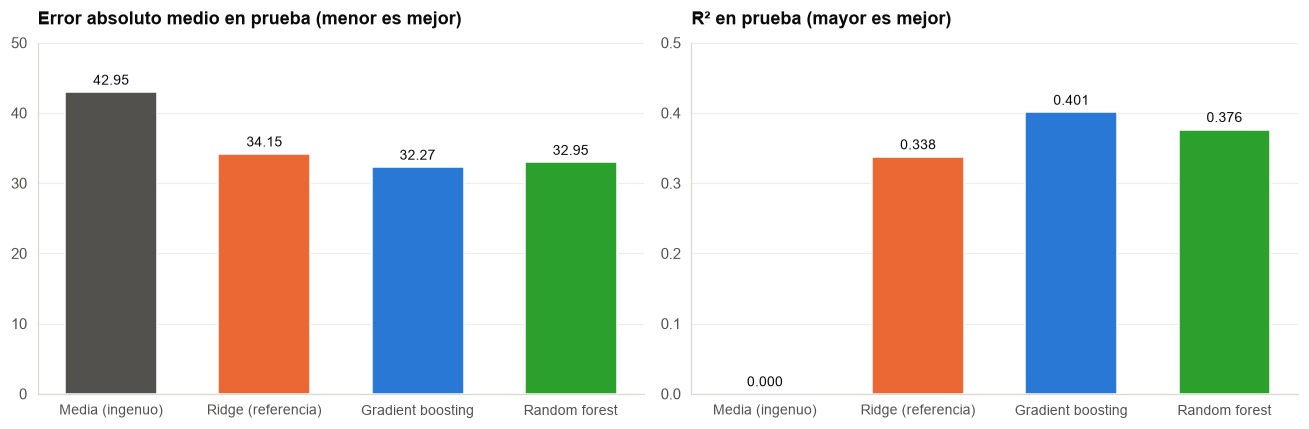

Mejor modelo en prueba: Gradient boosting (MAE 32.27, R² 0.401)


In [11]:
media = DummyRegressor(strategy="mean").fit(Xl_train, y_train)
modelos_todos = {"Media (ingenuo)": (media, "lineal"), **modelos}
tabla = tabla_metricas(modelos_todos, conjuntos)
tabla.to_csv(PROCESSED_DIR / "metricas_fase3.csv")
display(tabla)

prueba = tabla.xs("test", level="parte")
tiempos = pd.DataFrame({
    "búsqueda (s)": [0, 0, round(T_BUSQUEDA_HGB), round(T_BUSQUEDA_RF)],
    "entrenamiento final (s)": [0, 0, round(T_HGB), round(T_RF)],
    "sobreajuste (MAE train − test)": (tabla.xs("train", level="parte")["MAE"] - prueba["MAE"]).round(2).values,
}, index=prueba.index)
display(tiempos)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colores = [GRIS, C_RIDGE, C_HGB, C_RF]
for ax, metrica, titulo in [(axes[0], "MAE", "Error absoluto medio en prueba (menor es mejor)"),
                            (axes[1], "R2", "R² en prueba (mayor es mejor)")]:
    bars = ax.bar(prueba.index, prueba[metrica], color=colores, width=0.6)
    ax.bar_label(bars, labels=[f"{v:.2f}" if metrica == "MAE" else f"{v:.3f}" for v in prueba[metrica]], padding=3, fontsize=9)
    ax.set_title(titulo); ax.tick_params(axis="x", labelsize=9); ax.grid(axis="x", visible=False)
axes[0].set_ylim(0, 50); axes[1].set_ylim(0, 0.5)
fig.tight_layout()
save_fig(fig, "model_comparison")
plt.show()

pred_test = pd.DataFrame({"y_real": y_test}, index=y_test.index)
for nombre, (m, rep) in modelos_todos.items():
    pred_test["pred_" + nombre.split(" ")[0].lower().replace("(", "")] = m.predict(conjuntos[rep]["test"][0])
pred_test.to_parquet(PROCESSED_DIR / "predicciones_fase3.parquet")
MEJOR = prueba["MAE"].idxmin()
print(f"Mejor modelo en prueba: {MEJOR} (MAE {prueba.loc[MEJOR, 'MAE']:.2f}, R² {prueba.loc[MEJOR, 'R2']:.3f})")

La tabla y el gráfico resumen la fase. En prueba:

| Modelo | MAE | RMSE | R² | Sobreajuste (MAE) | Costo total |
|---|---|---|---|---|---|
| Media (ingenuo) | 42,95 | 51,80 | 0,000 | — | — |
| Ridge (referencia) | 34,15 | 42,17 | 0,338 | −0,05 | segundos |
| **Gradient boosting** | **32,27** | **40,10** | **0,401** | −0,37 | 56 s |
| Random forest | 32,95 | 40,91 | 0,376 | −2,74 | 82 s |

El **gradient boosting es el mejor modelo** por las tres métricas, con el menor sobreajuste y el menor costo de entrenamiento final. Los dos modelos de árboles superan a la referencia lineal, lo que confirma que la ganancia proviene de capturar no linealidades e interacciones, no de un algoritmo en particular; que el boosting supere al bosque con árboles diez veces más pequeños indica que esas no linealidades son suaves y aditivas en su mayoría (educación, edad, jornada), no interacciones profundas.

Conviene leer las cifras con perspectiva: pasar de R² 0,338 a 0,401 es una mejora real pero acotada. Con variables que describen el contexto del estudiante y no su desempeño individual, cerca del 60 % de la variación del puntaje queda fuera del alcance de cualquier modelo, y las tres familias convergen hacia el mismo techo (32 a 33 puntos de MAE). Las predicciones de los cuatro modelos sobre el conjunto de prueba quedan guardadas para el cuaderno de la fase 4.

## 8. Interpretabilidad del mejor modelo

### 8.1 Importancia por permutación

La importancia por permutación mide cuánto empeora el MAE del modelo cuando se barajan los valores de una variable en el conjunto de prueba, destruyendo su relación con el puntaje pero conservando su distribución. Es independiente del algoritmo y, a diferencia de los coeficientes de la fase 2, no se confunde con la colinealidad: una variable redundante con otra mostrará importancia baja porque el modelo puede compensarla. Se calcula sobre 5.000 filas de prueba con 5 repeticiones para el boosting y para el *random forest*, y se guarda en `data/processed/importancias.csv`.

Importancia por permutación (5.000 filas × 5 repeticiones × 2 modelos): 21 s


Figura guardada: assets\images\data\permutation_importance.png


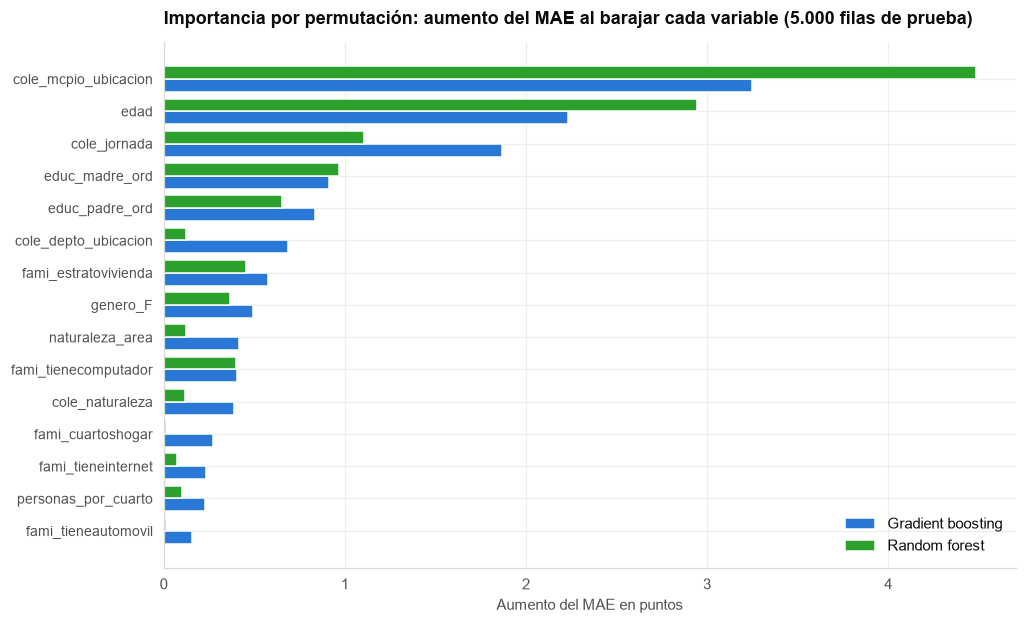

,cole_mcpio_ubicacion,edad,cole_jornada,educ_madre_ord,educ_padre_ord,cole_depto_ubicacion,fami_estratovivienda,genero_F,naturaleza_area,fami_tienecomputador,cole_naturaleza,fami_cuartoshogar,fami_tieneinternet,personas_por_cuarto,fami_tieneautomovil
Gradient boosting,3.250,2.230,1.870,0.910,0.840,0.690,0.580,0.490,0.420,0.400,0.390,0.270,0.230,0.230,0.160
Random forest,4.480,2.940,1.100,0.970,0.650,0.120,0.460,0.370,0.130,0.400,0.120,0.020,0.070,0.100,0.010


In [12]:
sel = np.random.default_rng(RANDOM_STATE).choice(len(Xa_test), 5_000, replace=False)
Xa_muestra, y_muestra = Xa_test.iloc[sel], y_test.iloc[sel]

t0 = time.time()
importancias = {}
for nombre in ["Gradient boosting", "Random forest"]:
    m = modelos[nombre][0]
    pi = permutation_importance(m, Xa_muestra, y_muestra, scoring="neg_mean_absolute_error",
                                n_repeats=5, random_state=RANDOM_STATE, n_jobs=N_JOBS)
    importancias[nombre] = pd.Series(pi.importances_mean, index=COLS_ARBOLES)
importancias = pd.DataFrame(importancias)
importancias.to_csv(PROCESSED_DIR / "importancias.csv")
print(f"Importancia por permutación (5.000 filas × 5 repeticiones × 2 modelos): {time.time() - t0:.0f} s")

top = importancias.sort_values("Gradient boosting", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 6.2))
yy = np.arange(len(top))
ax.barh(yy + 0.2, top["Gradient boosting"], height=0.4, color=C_HGB, label="Gradient boosting")
ax.barh(yy - 0.2, top["Random forest"], height=0.4, color=C_RF, label="Random forest")
ax.set_yticks(yy); ax.set_yticklabels(top.index, fontsize=9); ax.invert_yaxis()
ax.set_title("Importancia por permutación: aumento del MAE al barajar cada variable (5.000 filas de prueba)")
ax.set_xlabel("Aumento del MAE en puntos"); ax.legend(frameon=False)
save_fig(fig, "permutation_importance")
plt.show()
display(top.round(2).T)

Los dos modelos de árboles coinciden en las cuatro variables más importantes: el **municipio del colegio** (barajarlo sube el MAE 3,25 puntos en el boosting y 4,48 en el bosque), la **edad** (2,23 y 2,94), la **jornada** (1,87 y 1,10) y la **educación de la madre** (0,91 y 0,97), seguidas de la educación del padre, el departamento, el estrato y el género. Tres observaciones:

*   El municipio codificado por objetivo es la variable más valiosa de todas: resume el contexto local (oferta educativa, ruralidad, nivel socioeconómico del entorno) mejor que cualquier otra. Es también la que explica buena parte de la mejora respecto del ajuste exploratorio de la fase 1, que no la tenía.
*   Las variables del hogar pesan menos de lo que sugería su correlación bivariada porque son **redundantes entre sí**: internet, computador, estrato y educación de los padres miden el mismo nivel socioeconómico, y al barajar una el modelo se apoya en las otras. Por eso la importancia por permutación subestima a cada una por separado, aunque el bloque en conjunto sea decisivo.
*   `cole_area_ubicacion` y `cole_caracter` no aparecen entre las quince primeras del boosting: una vez conocidos el municipio y la combinación naturaleza × área, el área rural o urbana por sí sola no añade información, lo que confirma la decisión de la fase 1 de crear la interacción.

### 8.2 Valores SHAP

Los valores SHAP descomponen cada predicción individual en la contribución de cada variable, de modo que no solo dicen qué variable importa sino **en qué dirección y para quién**. Toda descomposición SHAP debe cumplir la propiedad de **aditividad**: la suma de las contribuciones más el valor base tiene que reproducir la predicción del modelo. La celda lo verifica antes de usar cualquier resultado.

El explicador rápido para árboles (`TreeExplainer`) es el candidato natural, pero **no interpreta las divisiones categóricas** que el boosting de scikit-learn usa en las 17 variables nominales: las trata como umbrales numéricos y produce atribuciones que no suman la predicción. Por eso la celda mide su error de aditividad y, si supera un punto, pasa al **explicador por permutación**, que es agnóstico al modelo, exacto por construcción y solo necesita evaluar `predict` sobre combinaciones de valores. Como es más lento, se aplica a 1.000 de las 5.000 filas de interpretación, con 100 filas de entrenamiento como fondo. El gráfico de enjambre muestra la distribución de contribuciones de las 15 variables principales, coloreadas por el valor de la variable (rojo alto, azul bajo); para las categóricas el color corresponde al código entero, por lo que su dirección se lee mejor en la dependencia parcial de la sección siguiente.

TreeExplainer: 1 s · error de aditividad medio 38.5 puntos


explicador por permutación (agnóstico): 42 s · error de aditividad medio 0.000 puntos


Figura guardada: assets\images\data\shap_beeswarm.png


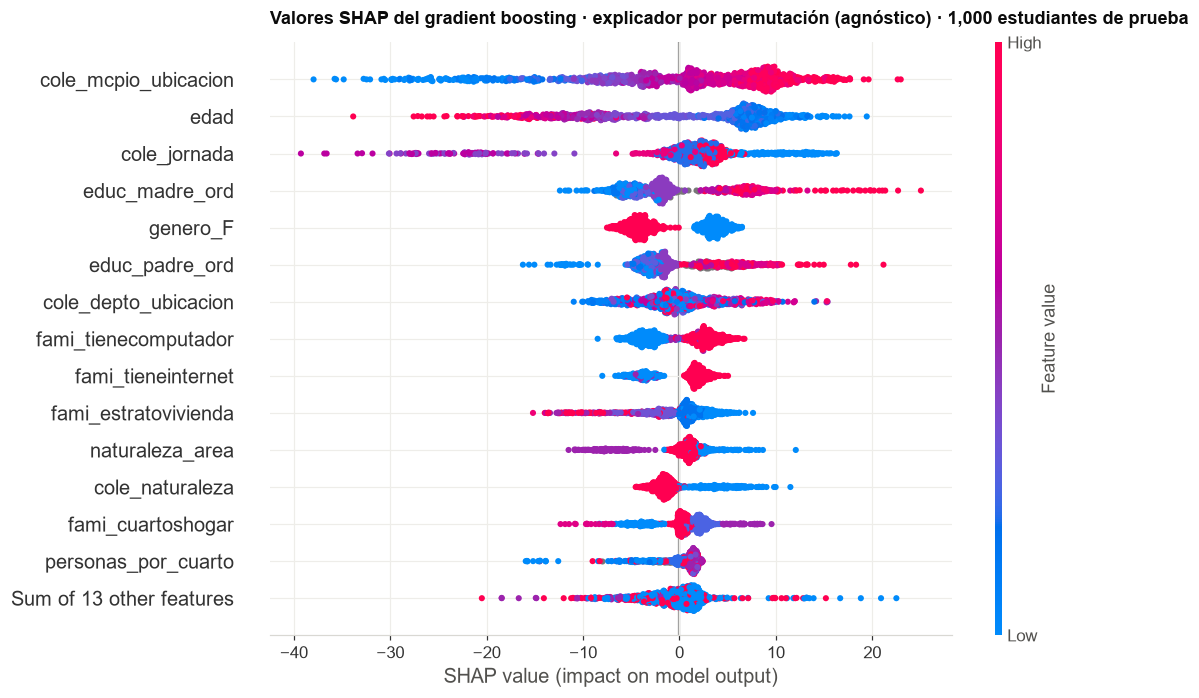

,cole_mcpio_ubicacion,edad,cole_jornada,educ_madre_ord,genero_F,educ_padre_ord,cole_depto_ubicacion,fami_tienecomputador,fami_tieneinternet,fami_estratovivienda,naturaleza_area,cole_naturaleza
|SHAP| medio (puntos),8.900,8.700,5.270,4.800,4.040,3.850,3.350,3.120,2.570,2.520,2.360,2.190


In [13]:
sel_shap = np.random.default_rng(RANDOM_STATE).choice(len(Xa_muestra), 1_000, replace=False)
Xa_shap = Xa_muestra.iloc[sel_shap]
pred_shap = hgb.predict(Xa_shap)

def error_aditividad(valores):
    return float(np.abs(valores.values.sum(axis=1) + valores.base_values - pred_shap).mean())

t0 = time.time()
sv_tree = shap.TreeExplainer(hgb)(Xa_shap, check_additivity=False)
err_tree = error_aditividad(sv_tree)
print(f"TreeExplainer: {time.time() - t0:.0f} s · error de aditividad medio {err_tree:.1f} puntos")

if err_tree > 1:
    t0 = time.time()
    fondo = Xa_train.iloc[np.random.default_rng(RANDOM_STATE).choice(len(Xa_train), 100, replace=False)]
    explainer = shap.Explainer(hgb.predict, shap.maskers.Independent(fondo, max_samples=100), algorithm="permutation", seed=RANDOM_STATE)
    shap_values = explainer(Xa_shap, max_evals=2 * Xa_shap.shape[1] + 1, silent=True)
    metodo = "explicador por permutación (agnóstico)"
    print(f"{metodo}: {time.time() - t0:.0f} s · error de aditividad medio {error_aditividad(shap_values):.3f} puntos")
else:
    shap_values, metodo = sv_tree, "TreeExplainer"

shap_abs = pd.Series(np.abs(shap_values.values).mean(axis=0), index=COLS_ARBOLES).sort_values(ascending=False)
shap_abs.to_csv(PROCESSED_DIR / "shap_importancia.csv")

fig = plt.figure(figsize=(10, 7))
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title(f"Valores SHAP del gradient boosting · {metodo} · {len(Xa_shap):,} estudiantes de prueba", loc="left", fontweight="bold")
plt.gcf().set_size_inches(10, 7)
save_fig(plt.gcf(), "shap_beeswarm")
plt.show()
display(shap_abs.head(12).round(2).to_frame("|SHAP| medio (puntos)").T)

La verificación de aditividad resultó decisiva: `TreeExplainer` produce atribuciones que **se alejan 38,5 puntos** de la predicción real del modelo, es decir, no describen el boosting con variables categóricas, y en una ejecución preliminar llegaba a señalar como variables principales al área y al carácter del colegio, que la importancia por permutación coloca al final. El explicador por permutación, con error de aditividad 0,000, tarda 37 s para 1.000 estudiantes y da un ranking coherente con la sección anterior: municipio (|SHAP| medio 8,9 puntos), edad (8,7), jornada (5,3), educación de la madre (4,8), género (4,0), educación del padre (3,9), departamento (3,4), computador (3,1), internet (2,6) y estrato (2,5).

El enjambre añade la **dirección**. La edad tiene la cola más larga hacia la izquierda: para los estudiantes mayores (puntos rojos) la contribución llega a −35 puntos, mientras que para los de 16 y 17 años es un aporte pequeño y positivo. El municipio reparte entre −25 y +20 puntos según el valor codificado. En la educación de la madre los niveles altos (rojo) empujan hacia arriba hasta +25 y los bajos hacia abajo de forma más moderada. El género muestra dos nubes separadas: ser mujer (rojo) resta unos 4 puntos y ser hombre los suma. Tener computador e internet aporta entre +2 y +5 puntos y no tenerlos resta entre 3 y 8, una asimetría que un coeficiente lineal no distingue.

### 8.3 Dependencia parcial

La dependencia parcial muestra la predicción media del modelo cuando una variable recorre su rango y las demás se mantienen como están. Se grafica para la educación de la madre, la edad y las personas por cuarto, las tres variables numéricas más importantes, y para la jornada del colegio como ejemplo categórico (con las etiquetas originales recuperadas del codificador). Se usa el método *brute*, que evalúa el modelo sobre la muestra para cada valor de la rejilla, porque el método recursivo de scikit-learn no contempla las divisiones categóricas del boosting. Son las curvas que un modelo lineal solo puede aproximar con una recta.

Figura guardada: assets\images\data\partial_dependence.png


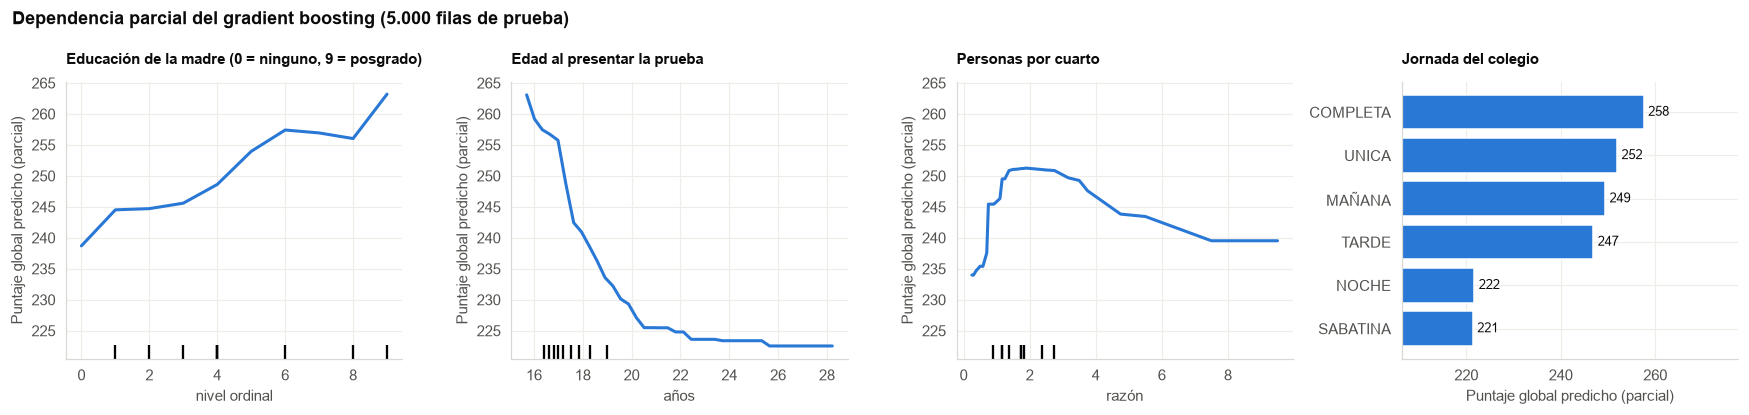

In [14]:
jornada_cats = prep_arboles.named_transformers_["nom"].categories_[NOM_COLS.index("cole_jornada")]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
PartialDependenceDisplay.from_estimator(hgb, Xa_muestra, ["educ_madre_ord", "edad", "personas_por_cuarto"],
                                        method="brute", kind="average", percentiles=(0.01, 0.99), grid_resolution=40,
                                        ax=axes[:3], line_kw={"color": C_HGB, "linewidth": 2}, random_state=RANDOM_STATE)
for ax, titulo, xl in zip(axes[:3], ["Educación de la madre (0 = ninguno, 9 = posgrado)", "Edad al presentar la prueba", "Personas por cuarto"],
                          ["nivel ordinal", "años", "razón"]):
    ax.set_title(titulo, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel("Puntaje global predicho (parcial)")

pd_jornada = []
col = COLS_ARBOLES.index("cole_jornada")
for k, etiqueta in enumerate(jornada_cats):
    Xtmp = Xa_muestra.copy(); Xtmp.iloc[:, col] = float(k)
    pd_jornada.append((etiqueta, hgb.predict(Xtmp).mean()))
pd_jornada = pd.Series(dict(pd_jornada)).sort_values()
bars = axes[3].barh(pd_jornada.index, pd_jornada.values, color=C_HGB)
axes[3].bar_label(bars, labels=[f"{v:.0f}" for v in pd_jornada.values], padding=3, fontsize=8.5)
axes[3].set_xlim(pd_jornada.min() - 15, pd_jornada.max() + 20)
axes[3].set_title("Jornada del colegio", fontsize=10); axes[3].set_xlabel("Puntaje global predicho (parcial)")
fig.suptitle("Dependencia parcial del gradient boosting (5.000 filas de prueba)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "partial_dependence")
plt.show()

Las curvas de dependencia parcial muestran las formas que la fase 2 solo podía aproximar con rectas:

*   **Educación de la madre**: la predicción sube de 239 puntos con *Ninguno* a 263 con *Postgrado*, pero no de forma lineal: es casi plana entre primaria incompleta y secundaria incompleta (245 a 246), sube con fuerza entre secundaria completa y técnica completa (249 a 257) y vuelve a saltar con el posgrado. Cada escalón educativo no vale lo mismo.
*   **Edad**: la caída es abrupta y luego se estabiliza: de 263 puntos a los 16 años a 242 a los 18, 229 a los 20 y 223 de los 22 en adelante. Dos años de extraedad cuestan tanto como todo el rango de educación de la madre.
*   **Personas por cuarto**: la relación en forma de U que detectó la fase 1 aparece con claridad: la predicción es máxima alrededor de 1,5 a 2 personas por cuarto (251 puntos), cae a 234 por debajo de 0,5 (hogares de una o dos personas en viviendas grandes, que suelen ser rurales) y baja a 240 a partir de 7 personas por cuarto.
*   **Jornada**: completa 258, única 252, mañana 249, tarde 247 y, muy por debajo, noche 222 y sabatina 221. La brecha de 36 puntos entre la completa y la nocturna se mantiene después de controlar la edad, así que no es solo un efecto de la extraedad.

## 9. Análisis de errores

Dos preguntas guían esta sección: **cuánto** se equivoca el mejor modelo en distintos tramos y grupos, y **si corrige** el sesgo por tramo que mostró el modelo lineal en la fase 2. Se calcula el residuo (real − predicho) del boosting y de Ridge sobre todo el conjunto de prueba y se compara por tramo de puntaje real, por naturaleza y área del colegio, por jornada y por departamento; además se mide qué fracción de estudiantes queda dentro de 25 y 50 puntos de su puntaje real, y se listan los diez casos peor predichos.

Por tramo de puntaje real:


tramo,"(0, 200]","(200, 250]","(250, 300]","(300, 350]","(350, 500]"
n,"15,524.000","26,372.000","23,352.000","12,332.000","2,338.000"
sesgo Ridge,-44.000,-17.500,15.800,48.100,80.000
MAE Ridge,45.800,25.700,23.800,48.600,80.000
sesgo boosting,-40.300,-15.900,15.100,43.600,69.800
MAE boosting,41.100,24.500,24.800,44.800,69.800


Por naturaleza y área del colegio:


cole_naturaleza     NO OFICIAL               OFICIAL           
cole_area_ubicacion      RURAL     URBANO      RURAL     URBANO
n                      764.000 17,288.000 12,912.000 48,955.000
sesgo Ridge              0.700      0.500      0.100     -0.100
MAE Ridge               35.900     36.800     30.500     34.100
sesgo boosting           0.800      0.700      0.100     -0.100
MAE boosting            33.100     34.100     28.600     32.600

Por jornada:


cole_jornada,COMPLETA,MAÑANA,NOCHE,SABATINA,TARDE,UNICA
n,"11,554.000","31,275.000","3,571.000","4,276.000","7,372.000","21,871.000"
sesgo Ridge,0.400,0.200,-0.400,0.800,-0.400,-0.200
MAE Ridge,34.900,34.700,30.300,30.800,34.400,34.200
sesgo boosting,0.400,0.200,-0.300,1.000,-0.400,-0.100
MAE boosting,32.700,32.800,27.800,27.800,32.700,32.800


Departamentos con menor y mayor MAE del boosting:


cole_depto_ubicacion,VAUPES,GUAINIA,CHOCO,AMAZONAS,ATLANTICO,NORTE SANTANDER,QUINDIO,SAN ANDRES
n,73.000,62.000,750.000,124.000,"4,675.000","2,443.000",850.000,87.000
sesgo Ridge,-2.300,-8.400,0.300,3.200,1.200,-0.700,1.800,-7.600
MAE Ridge,28.300,25.600,26.800,31.100,36.500,36.600,36.800,41.900
sesgo boosting,-2.500,-10.100,0.300,2.800,1.200,-0.200,2.000,-5.700
MAE boosting,23.900,24.200,24.700,26.900,34.400,34.900,35.100,35.500


,ridge,hgb
dentro de ±25 puntos (%),42.800,45.800
dentro de ±50 puntos (%),75.600,78.500


Figura guardada: assets\images\data\error_analysis.png


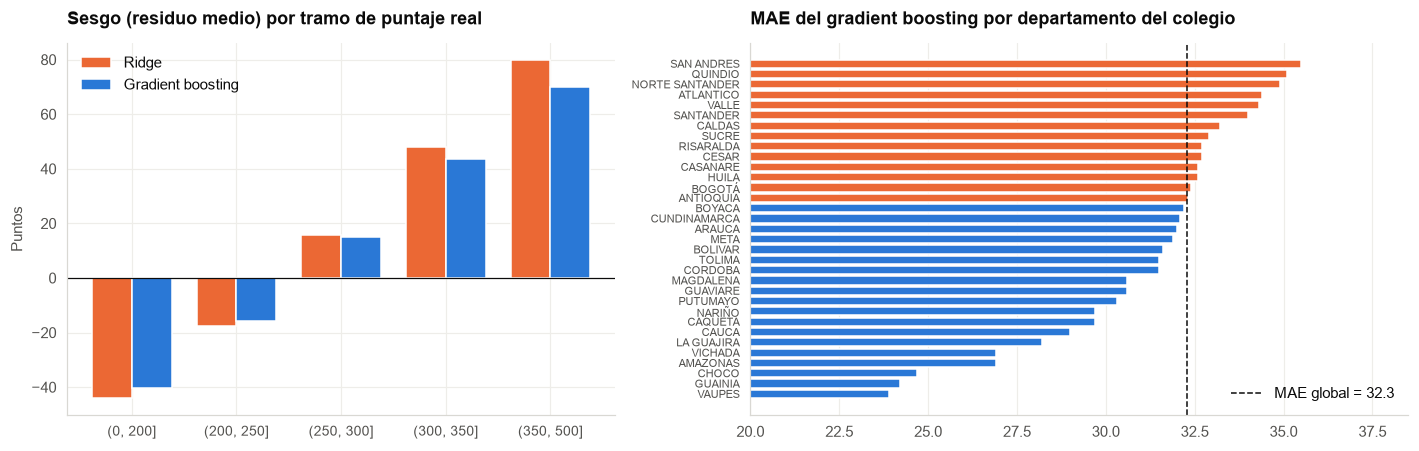

Los diez estudiantes peor predichos por el boosting:


,y_real,pred_boosting,hgb,cole_naturaleza,cole_area_ubicacion,cole_jornada,cole_depto_ubicacion,extraedad,educ_madre_ord,fami_estratovivienda,fami_tieneinternet
estu_consecutivo,,,,,,,,,,,
SB11202240208463,0.000,252.000,-252.000,OFICIAL,URBANO,MAÑANA,VALLE,0,NaN,No respondió,No respondió
SB11202240325863,14.000,211.000,-197.000,OFICIAL,URBANO,SABATINA,BOGOTÁ,1,3.000,No respondió,Si
SB11202240018711,456.000,269.000,187.000,NO OFICIAL,RURAL,COMPLETA,QUINDIO,0,4.000,Estrato 3,Si
SB11202240187362,443.000,266.000,177.000,OFICIAL,URBANO,UNICA,ANTIOQUIA,0,4.000,Estrato 2,Si
SB11202240377607,418.000,252.000,166.000,OFICIAL,URBANO,UNICA,ATLANTICO,0,4.000,Estrato 4,Si
SB11202240189223,362.000,199.000,163.000,OFICIAL,URBANO,NOCHE,BOLIVAR,1,6.000,Estrato 2,Si
SB11202240520411,415.000,253.000,162.000,OFICIAL,URBANO,MAÑANA,SUCRE,0,6.000,Estrato 2,No
SB11202240255075,138.000,300.000,-162.000,NO OFICIAL,URBANO,COMPLETA,CUNDINAMARCA,0,9.000,Estrato 3,Si
SB11202240140005,407.000,247.000,160.000,NO OFICIAL,URBANO,SABATINA,SANTANDER,0,9.000,Estrato 1,Si


In [15]:
err = pred_test[["y_real"]].copy()
err["ridge"] = pred_test["y_real"] - pred_test["pred_ridge"]
err["hgb"] = pred_test["y_real"] - pred_test["pred_gradient"]
err = err.join(df.loc[err.index, ["cole_naturaleza", "cole_area_ubicacion", "cole_jornada", "cole_depto_ubicacion", "extraedad"]])
err["tramo"] = pd.cut(err["y_real"], [0, 200, 250, 300, 350, 500])

def resumen(grupo):
    g = err.groupby(grupo, observed=True)
    return pd.DataFrame({"n": g.size(),
                         "sesgo Ridge": g["ridge"].mean(), "MAE Ridge": g["ridge"].apply(lambda s: s.abs().mean()),
                         "sesgo boosting": g["hgb"].mean(), "MAE boosting": g["hgb"].apply(lambda s: s.abs().mean())}).round(1)

print("Por tramo de puntaje real:"); display(resumen("tramo").T)
print("Por naturaleza y área del colegio:"); display(resumen(["cole_naturaleza", "cole_area_ubicacion"]).T)
print("Por jornada:"); display(resumen("cole_jornada").T)
dep = resumen("cole_depto_ubicacion").sort_values("MAE boosting")
print("Departamentos con menor y mayor MAE del boosting:"); display(pd.concat([dep.head(4), dep.tail(4)]).T)

dentro = pd.DataFrame({m: [(err[m].abs() <= 25).mean() * 100, (err[m].abs() <= 50).mean() * 100] for m in ["ridge", "hgb"]},
                      index=["dentro de ±25 puntos (%)", "dentro de ±50 puntos (%)"]).round(1)
display(dentro)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
tr = resumen("tramo")
x = np.arange(len(tr)); w = 0.38
axes[0].bar(x - w / 2, tr["sesgo Ridge"], w, color=C_RIDGE, label="Ridge")
axes[0].bar(x + w / 2, tr["sesgo boosting"], w, color=C_HGB, label="Gradient boosting")
axes[0].axhline(0, color=TINTA, linewidth=0.8)
axes[0].set_xticks(x); axes[0].set_xticklabels([str(i) for i in tr.index], fontsize=9)
axes[0].set_title("Sesgo (residuo medio) por tramo de puntaje real"); axes[0].set_ylabel("Puntos"); axes[0].legend(frameon=False)
axes[1].barh(dep.index, dep["MAE boosting"], color=[C_ACCENT if v > err["hgb"].abs().mean() else C_HGB for v in dep["MAE boosting"]])
axes[1].axvline(err["hgb"].abs().mean(), color=TINTA, linestyle="--", linewidth=1, label=f"MAE global = {err['hgb'].abs().mean():.1f}")
axes[1].set_title("MAE del gradient boosting por departamento del colegio"); axes[1].tick_params(axis="y", labelsize=7)
axes[1].set_xlim(20, dep["MAE boosting"].max() + 3); axes[1].legend(frameon=False, loc="lower right"); axes[1].grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "error_analysis")
plt.show()

peores = err.reindex(err["hgb"].abs().sort_values(ascending=False).index[:10])
peores = peores.join(df.loc[peores.index, ["educ_madre_ord", "fami_estratovivienda", "fami_tieneinternet"]])
peores.insert(1, "pred_boosting", (peores["y_real"] - peores["hgb"]).round(0))
print("Los diez estudiantes peor predichos por el boosting:")
display(peores.drop(columns=["ridge", "tramo"]).round(0))

El boosting **mejora en todos los cortes pero no elimina el sesgo por tramo**. Para los estudiantes de más de 350 puntos el residuo medio baja de 80 (Ridge) a 69,8; para los de menos de 200 sube de −44 a −40,3; en los tramos centrales el error ronda los 24 a 25 puntos. La compresión hacia la media es estructural: el modelo predice casi siempre entre 200 y 310, y los 2.338 estudiantes de más de 350 puntos tienen un contexto que, según el modelo, corresponde a unos 270. El 45,8 % de los estudiantes queda a 25 puntos o menos de su puntaje real y el 78,5 % a 50 o menos (frente a 42,8 % y 75,6 % de Ridge).

Por **grupos** el error es parejo y el sesgo nulo: entre 28,6 (oficial rural) y 34,1 (privado urbano) por naturaleza y área, y entre 27,8 (nocturna y sabatina) y 32,8 (mañana) por jornada. El modelo acierta más donde los puntajes son más homogéneos y bajos: los departamentos con menor MAE son Vaupés (23,9), Guainía (24,2), Chocó (24,7) y Amazonas (26,9), justamente los de menor puntaje medio, y los de mayor error son San Andrés (35,5), Quindío (35,1), Norte de Santander (34,9) y Atlántico (34,4). El único sesgo apreciable es Guainía (−10 puntos con 62 estudiantes), un grupo tan pequeño que la codificación del municipio no lo estabiliza.

Los **diez casos peor predichos** son de dos tipos. Dos estudiantes con puntaje 0 y 14 (probablemente pruebas anuladas o no presentadas en su totalidad) a los que el modelo asigna 252 y 211 según su contexto; y ocho estudiantes de puntajes entre 362 y 456 que provienen de colegios oficiales de jornada mañana, única o incluso nocturna, con madres de secundaria o técnica, a quienes el modelo predice entre 199 y 269 puntos. Son los talentos que el contexto no anticipa, y constituyen el límite ético y estadístico de este tipo de modelo: nunca debería usarse para decidir sobre un estudiante individual, solo para describir desigualdades estructurales.

## 10. Conclusiones de la fase 3

*   Se entrenaron y compararon dos modelos adicionales al de referencia con hiperparámetros ajustados por validación cruzada. El **gradient boosting por histogramas es el mejor modelo del proyecto**: MAE de 32,27 puntos, RMSE de 40,10 y R² de 0,401 en prueba, frente a 34,15 / 42,17 / 0,338 de Ridge y 32,95 / 40,91 / 0,376 del *random forest*, con el menor sobreajuste (0,37 puntos de MAE) y un entrenamiento final de segundos.

*   Las ganancias provienen de la **no linealidad**, no del algoritmo: ambos modelos de árboles superan a la referencia lineal y convergen hacia el mismo techo de 32 a 33 puntos. Con variables de contexto y no de desempeño individual, cerca del 60 % de la variación del puntaje permanece inexplicada, y el modelo comprime los extremos: subestima en 70 puntos a quienes superan 350 y sobreestima en 40 a quienes no llegan a 200.

*   La interpretación es consistente entre tres métodos independientes (permutación, SHAP y dependencia parcial): las variables decisivas son el **municipio del colegio, la edad, la jornada y la educación de los padres**, seguidas del género, el departamento y el acceso a computador e internet. Las curvas parciales muestran escalones desiguales en la educación de la madre, una caída de 40 puntos entre los 16 y los 22 años, la forma de U del hacinamiento y 36 puntos de brecha entre la jornada completa y la nocturna. Las variables del hogar pesan menos individualmente de lo que sugería la fase 1 porque son redundantes entre sí.

*   Una verificación metodológica evitó una conclusión falsa: `TreeExplainer` no soporta las divisiones categóricas del boosting de scikit-learn y produce atribuciones con 38,5 puntos de error de aditividad; el explicador por permutación, exacto, dio un ranking coherente con los otros métodos. Comprobar la aditividad debería ser parte de cualquier uso de SHAP.

*   El error es parejo entre grupos (28 a 35 puntos de MAE por naturaleza, área, jornada y departamento) y sin sesgo sistemático, pero los casos peor predichos son estudiantes de colegios oficiales con puntajes sobresalientes que su contexto no anticipa. El modelo describe desigualdades estructurales; no sirve, ni debe usarse, para decidir sobre un estudiante individual. Con los modelos, las métricas, las importancias y las predicciones guardadas, la fase 4 se dedica a comunicar estos resultados.